In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from nixtla import NixtlaClient

In [2]:
print("NIXTLA_API_KEY:", "FOUND" if "NIXTLA_API_KEY" in os.environ else "NOT FOUND")

NIXTLA_API_KEY: FOUND


In [3]:
# set via env var
assert "NIXTLA_API_KEY" in os.environ, "Set env var NIXTLA_API_KEY dulu"
client = NixtlaClient()

In [4]:
TICKER = "BNB-USD"
H = 1

DATA_LONG_PATH = "../data/raw/crypto_yahoo_1d_2015-01-01_to_2025-12-19_LONG.csv"

DATE_COL = "Date"
TICKER_COL = "Ticker"
TARGET_COL = "Close"

TRAIN_RATIO = 0.70
VAL_RATIO   = 0.15
TEST_RATIO  = 0.15

MAX_HISTORY = 60    # fairness: hanya 60 hari terakhir seperti input Attention-LSTM

In [5]:
# Load & Prepare Data
df = pd.read_csv(DATA_LONG_PATH)
df[DATE_COL] = pd.to_datetime(df[DATE_COL])

df = df[[DATE_COL, TICKER_COL, TARGET_COL]].dropna()
df = df.sort_values([TICKER_COL, DATE_COL]).reset_index(drop=True)

df_one = df[df[TICKER_COL] == TICKER].copy().sort_values(DATE_COL).reset_index(drop=True)

print("df_one shape:", df_one.shape)
display(df_one.head(), df_one.tail())

df_one shape: (2963, 3)


,Date,Ticker,Close
0,2017-11-09,BNB-USD,1.99077
1,2017-11-10,BNB-USD,1.79684
2,2017-11-11,BNB-USD,1.67047
3,2017-11-12,BNB-USD,1.51969
4,2017-11-13,BNB-USD,1.68662


,Date,Ticker,Close
2958,2025-12-15,BNB-USD,858.545105
2959,2025-12-16,BNB-USD,874.899048
2960,2025-12-17,BNB-USD,842.930176
2961,2025-12-18,BNB-USD,829.301147
2962,2025-12-19,BNB-USD,850.505981


In [6]:
# Split Train/Val/Test
def split_ts(df_one):
    n = len(df_one)
    n_train = int(n * TRAIN_RATIO)
    n_val = int(n * VAL_RATIO)

    train = df_one.iloc[:n_train].copy()
    val   = df_one.iloc[n_train:n_train+n_val].copy()
    test  = df_one.iloc[n_train+n_val:].copy()
    return train, val, test

train, val, test = split_ts(df_one)
print("train/val/test:", len(train), len(val), len(test))

train/val/test: 2074 444 445


In [7]:
# Convert to TimeGPT format
def to_timegpt_df(df_part, uid):
    out = df_part.rename(columns={DATE_COL: "ds", TARGET_COL: "y"}).copy()
    out["unique_id"] = uid
    return out[["unique_id", "ds", "y"]]

hist_df = pd.concat([train, val]).reset_index(drop=True)  # history = train + val
df_hist = to_timegpt_df(hist_df, TICKER)
df_test = to_timegpt_df(test, TICKER)

display(df_hist.head(), df_test.head())

,unique_id,ds,y
0,BNB-USD,2017-11-09,1.99077
1,BNB-USD,2017-11-10,1.79684
2,BNB-USD,2017-11-11,1.67047
3,BNB-USD,2017-11-12,1.51969
4,BNB-USD,2017-11-13,1.68662


,unique_id,ds,y
2518,BNB-USD,2024-10-01,547.997131
2519,BNB-USD,2024-10-02,542.712341
2520,BNB-USD,2024-10-03,544.424988
2521,BNB-USD,2024-10-04,555.384216
2522,BNB-USD,2024-10-05,563.209167


In [8]:
# Rolling forecast (NO BLOCK; H tetap 60; ambil step-1)
def rolling_forecast_timegpt_step1_from_h60(client, hist_df, test_df, h=60, max_history=60):
    preds_step1 = []
    history = hist_df.copy().reset_index(drop=True)
    test_df = test_df.copy().reset_index(drop=True)

    for i in range(len(test_df)):
        row = test_df.iloc[i:i+1].copy()

        # fairness: batasi history 60 terakhir
        if max_history is not None and len(history) > max_history:
            history_input = history.iloc[-max_history:].copy()
        else:
            history_input = history

        fcst = client.forecast(
            df=history_input,
            h=h,
            time_col="ds",
            target_col="y",
            id_col="unique_id",
        )

        pred_col = "TimeGPT" if "TimeGPT" in fcst.columns else fcst.columns[-1]

        # ambil step-1 saja (baris pertama output forecast)
        yhat_step1 = float(fcst[pred_col].iloc[0])
        preds_step1.append(yhat_step1)

        # update history dengan aktual (walk-forward)
        history = pd.concat([history, row], ignore_index=True)

    return np.array(preds_step1)

y_pred = rolling_forecast_timegpt_step1_from_h60(
    client,
    df_hist,
    df_test,
    h=H,
    max_history=MAX_HISTORY
)

y_true = df_test["y"].values

print("len(y_pred):", len(y_pred))
print("len(y_true):", len(y_true))
assert len(y_pred) == len(y_true), "Mismatch panjang prediksi vs aktual"

INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Inferred freq: D
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Querying model metadata...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Inferred freq: D
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Inferred freq: D
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla_client:Calling Forecast Endpoint...
INFO:nixtla.nixtla_client:Validating inputs...
INFO:nixtla.nixtla_client:Inferred freq: D
INFO:nixtla.nixtla_client:Preprocessing dataframes...
INFO:nixtla.nixtla_client:Restricting input...
INFO:nixtla.nixtla

len(y_pred): 445
len(y_true): 445


In [9]:
# Metrics
def rmse(y_true, y_pred):
    return float(np.sqrt(np.mean((y_pred - y_true) ** 2)))

def mae(y_true, y_pred):
    return float(np.mean(np.abs(y_pred - y_true)))

def mape(y_true, y_pred, eps=1e-8):
    return float(np.mean(np.abs((y_true - y_pred) / (y_true + eps))) * 100.0)

metrics = {
    "ticker": TICKER,
    "mode": "close",
    "H": H,                    # horizon yang diminta (tetap 60)
    "eval_step": 1,            # yang dievaluasi step-1 (next-day)
    "max_history": MAX_HISTORY,
    "test_RMSE": rmse(y_true, y_pred),
    "test_MAE": mae(y_true, y_pred),
    "test_MAPE": mape(y_true, y_pred),
}
metrics

{'ticker': 'BNB-USD',
 'mode': 'close',
 'H': 1,
 'eval_step': 1,
 'max_history': 60,
 'test_RMSE': 26.562894497558425,
 'test_MAE': 17.100981276378157,
 'test_MAPE': 2.1826739638378023}

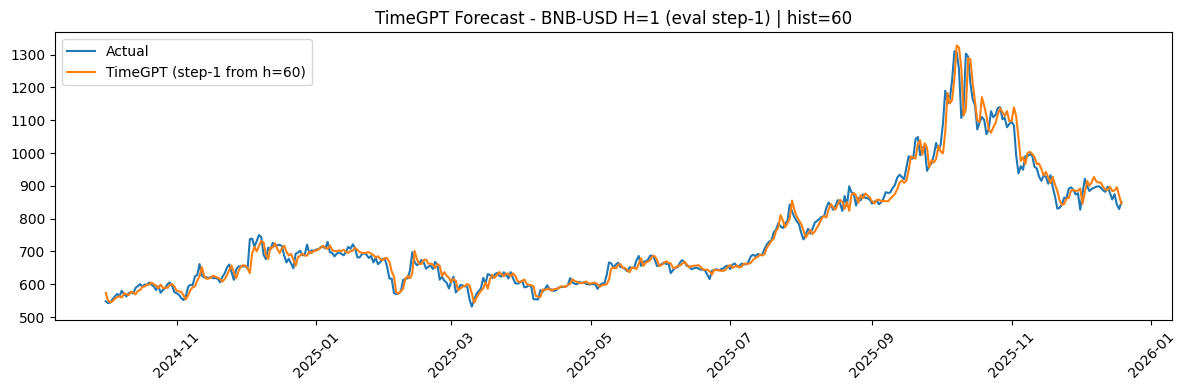

In [10]:
# Plot (Full test)
plt.figure(figsize=(12,4))
plt.plot(df_test["ds"], y_true, label="Actual")
plt.plot(df_test["ds"], y_pred, label="TimeGPT (step-1 from h=60)")
plt.xticks(rotation=45)
plt.title(f"TimeGPT Forecast - {TICKER} H={H} (eval step-1) | hist={MAX_HISTORY}")
plt.legend()
plt.tight_layout()
plt.show()

In [11]:
# Save metrics
os.makedirs("../models/timegpt", exist_ok=True)
out_path = f"../models/timegpt/metrics_{TICKER}_H{H}_close_hist{MAX_HISTORY}_step1.csv"
pd.DataFrame([metrics]).to_csv(out_path, index=False)
print("Saved:", out_path)

Saved: ../models/timegpt/metrics_BNB-USD_H1_close_hist60_step1.csv


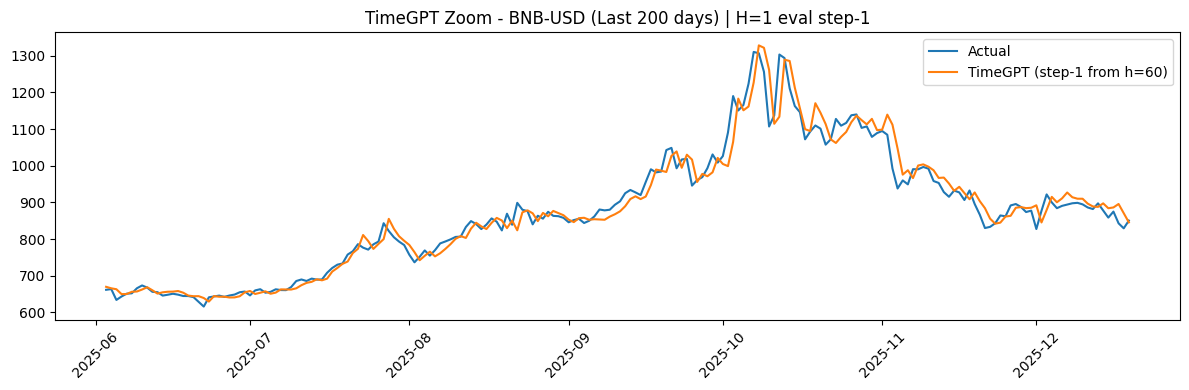

In [12]:
# Plot (Zoom last N days)
N = 200
plt.figure(figsize=(12,4))
plt.plot(df_test["ds"].iloc[-N:], y_true[-N:], label="Actual")
plt.plot(df_test["ds"].iloc[-N:], y_pred[-N:], label="TimeGPT (step-1 from h=60)")
plt.xticks(rotation=45)
plt.title(f"TimeGPT Zoom - {TICKER} (Last {N} days) | H={H} eval step-1")
plt.legend()
plt.tight_layout()
plt.show()